<a href="https://colab.research.google.com/github/Haarsh-G/mylib/blob/main/mechProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Basic Engineering Mechanics Project - Group 17
by
- Harsh Govind - 26AE10036
- Jay Wakale - 26AE10038
- Rishit Bhaumik - 26AE10016
- Gopesh Garodia - 26AE10013
- Vibhor Bhavsar - 26AE10064

### Question
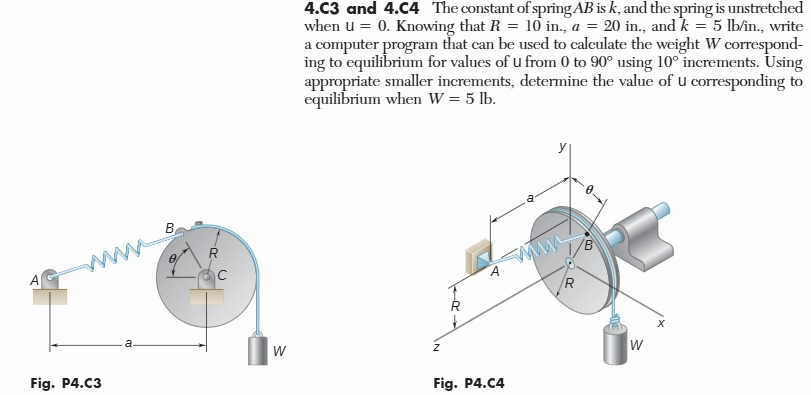

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# Given Parameters
R = 10 #inches (radius of wheel)
a = 20 #inches (perpendicular distance between wheel and point A)
k = 5 #lb/in (spring constant of the spring)
quesW = 5 #lb (weight for one of the case)
theta = sp.symbols("theta")
W = sp.symbols("W")

## Question 4.C3

#### Free Body Diagram
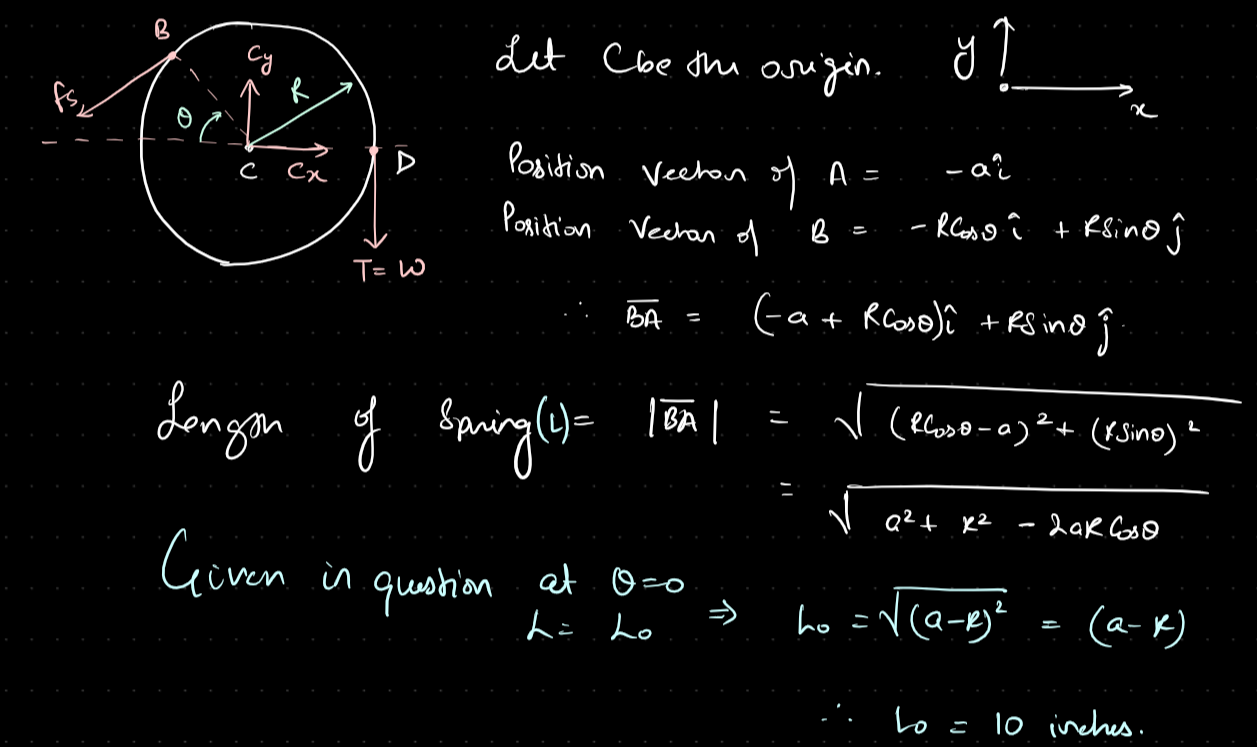

In [2]:
# Position Vectors for different points
A = sp.Array([-a,0,0])
B = sp.Array([-1*R*sp.cos(theta),R*sp.sin(theta),0])
BA = A - B

L0 = a - R
L = sp.sqrt(np.dot(BA,BA))
L = sp.simplify(sp.expand_trig(L))
unitBA = BA/L

print("Length of Spring")
display(L)

Length of Spring


10*sqrt(5 - 4*cos(theta))

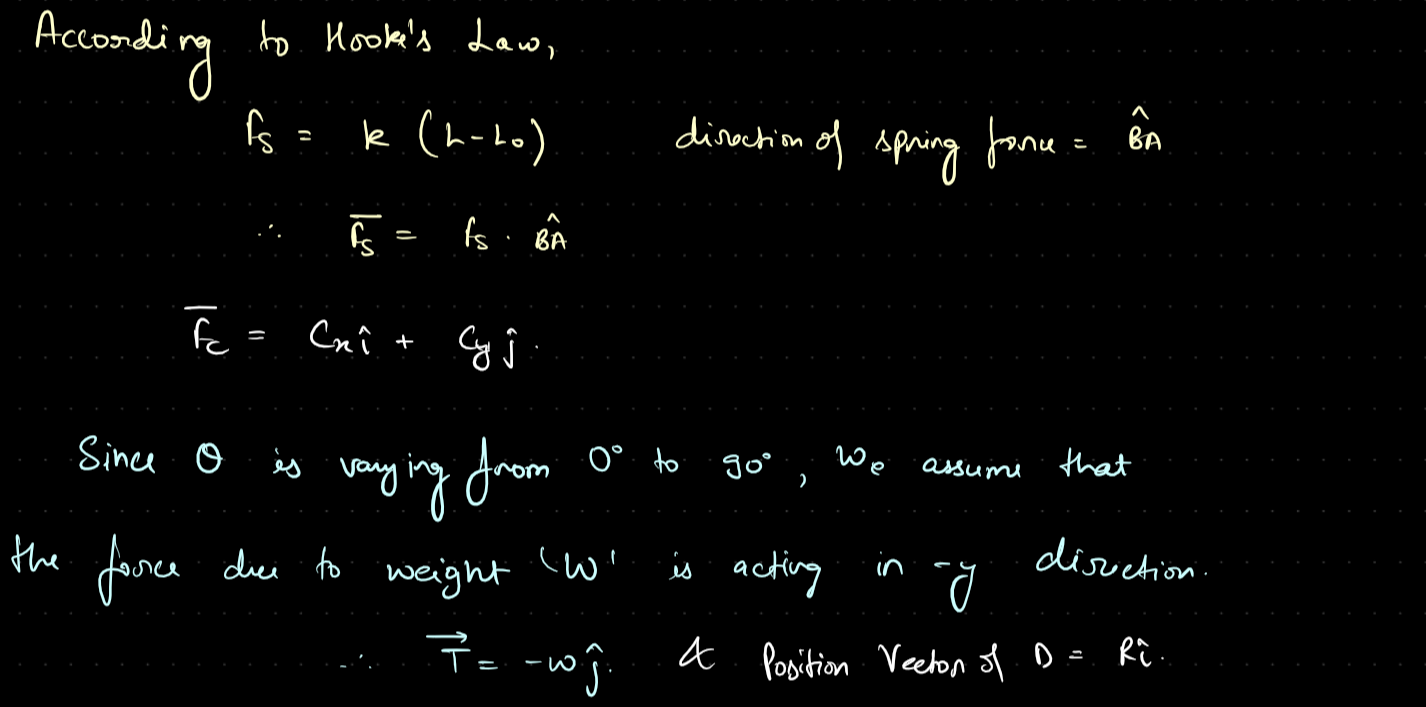

In [3]:
#Spring Force

F = k*(L - L0)*unitBA
print("Spring Force")
display(sp.simplify(F))

Spring Force


[50*(sqrt(5 - 4*cos(theta)) - 1)*(cos(theta) - 2)/sqrt(5 - 4*cos(theta)), 50*(-1 + 1/sqrt(5 - 4*cos(theta)))*sin(theta), 0]

#### Since we only need to find the relation between Weight W and the spring force, we can balance the moment about point C (the Z axis).

In [4]:
#Equilibrium

momentF = np.cross(B,F)
momentFz = sp.trigsimp(sp.simplify(momentF[2]))

momentBalance = sp.Eq(momentFz - W*R, 0)
funcW = sp.solve(momentBalance, W)[0]
W = sp.trigsimp(sp.simplify(funcW))

print("Moment balance about the Z-axis")
display(momentBalance)

# solved and simplified the equation of W in terms of θ (theta)
print("Weight as a function of theta")
print()
print("W(θ) = ", end=" ")
display(funcW)

Moment balance about the Z-axis


Eq(-10*W + 1000*(1 - 1/sqrt(5 - 4*cos(theta)))*sin(theta), 0)

Weight as a function of theta

W(θ) =  

100*(1 - 1/sqrt(5 - 4*cos(theta)))*sin(theta)

In [5]:
funcW = sp.lambdify(theta,W,"numpy")

angles_deg = np.arange(0,91,10)
angles_rad = np.deg2rad(angles_deg)

weights = funcW(angles_rad)

print("Angles | Weight (lb)")
print("-------------------------------")
for angle,weight in zip(angles_deg,weights):
    print(f"{angle:15.0f} | {weight:10.5f}")

Angles | Weight (lb)
-------------------------------
              0 |    0.00000
             10 |    0.50473
             20 |    3.50291
             30 |    9.65509
             40 |   18.07953
             50 |   27.45103
             60 |   36.60254
             70 |   44.66123
             80 |   51.01896
             90 |   55.27864


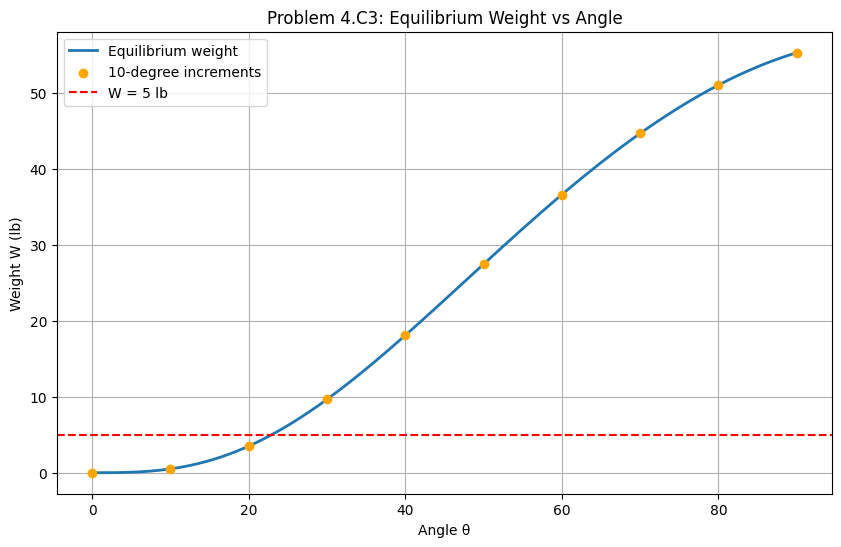

In [6]:
theta_deg = np.linspace(0,90,1000)
theta_rad = np.deg2rad(theta_deg)

plotW = funcW(theta_rad)

plt.figure(figsize=(10,6))
plt.plot(theta_deg, plotW,
         label="Equilibrium weight",
         linewidth=2)

plt.scatter(angles_deg, weights,
            label="10-degree increments",
            color="orange", zorder=3)

plt.axhline(y=5, color="red",
            linestyle="--", label="W = 5 lb")

plt.xlabel("Angle θ")
plt.ylabel("Weight W (lb)")
plt.title("Problem 4.C3: Equilibrium Weight vs Angle")

plt.grid(True)
plt.legend()
plt.show()

In [7]:
solTheta = sp.nsolve(W -5, theta,0.4)
degSolTheta = float(sp.deg(solTheta))

W_check = float(W.subs(theta,solTheta))

print(f"Equilibrium angle: {degSolTheta:.6f} degrees")
print(f"Weight at equilibrium: {W_check:.6f} lb")

Equilibrium angle: 22.931419 degrees
Weight at equilibrium: 5.000000 lb


#### Checking if the answer matches with the given answer
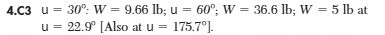

## Question 4.C4
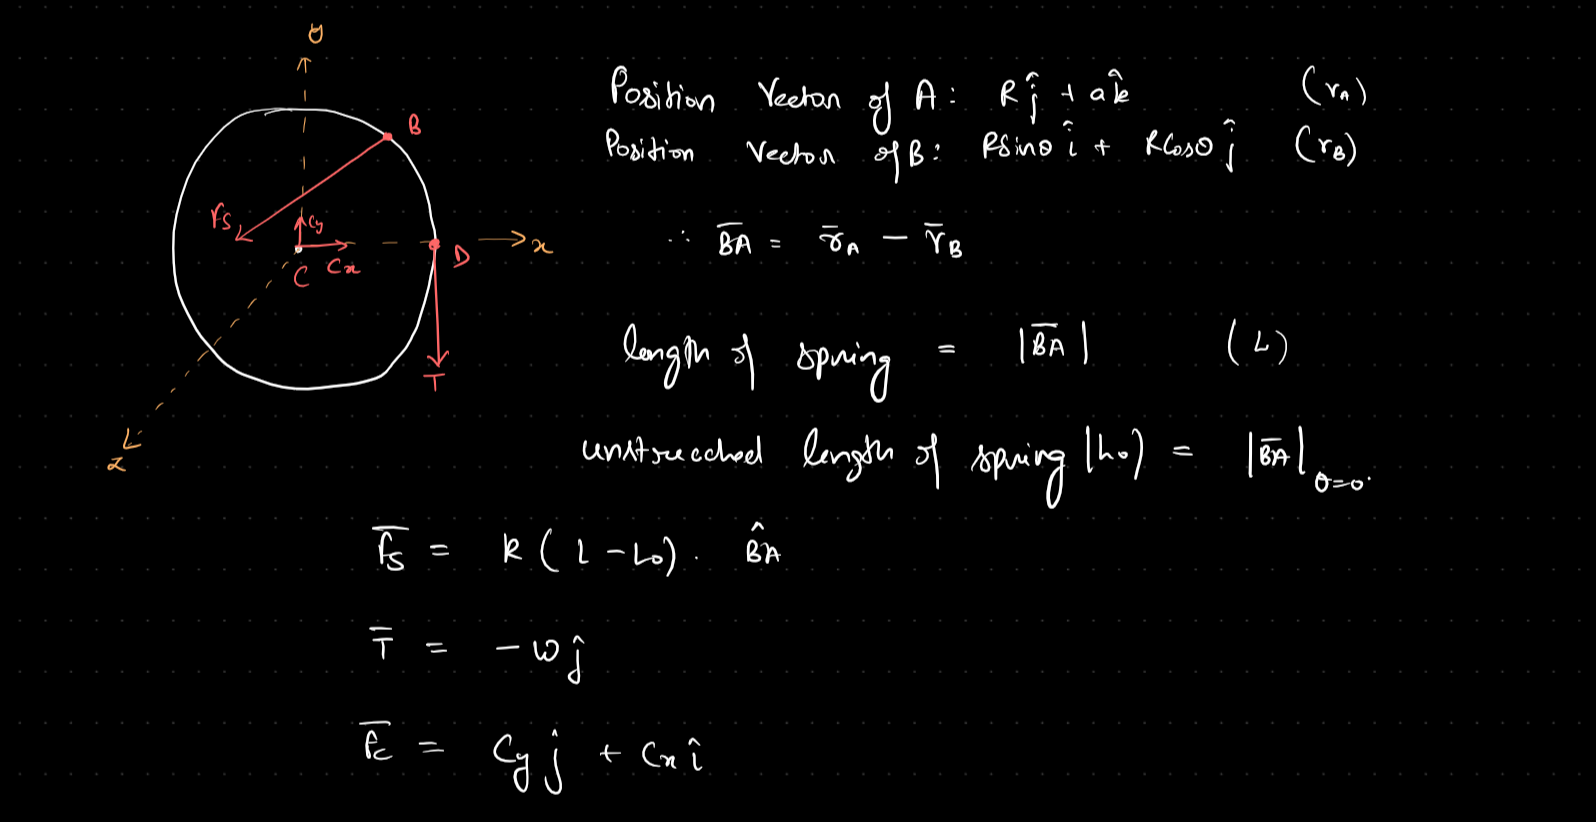

In [8]:
#3D definition of Vectors
W = sp.symbols("W")
A = sp.Array([0,R,a])
B = sp.Array([R*sp.sin(theta),R*sp.cos(theta),0])
BA = A - B

print("Vector BA")
display(BA)

Vector BA


[-10*sin(theta), 10 - 10*cos(theta), 20]

In [9]:
L0 = a
L = sp.sqrt(np.dot(BA,BA))
L = sp.simplify(sp.expand_trig(L))
unitBA = BA/L

print("Length of Spring")
display(L)

F = k*(L - L0)*unitBA
print("Spring Force")
display(sp.simplify(F))

Length of Spring


10*sqrt(6 - 2*cos(theta))

Spring Force


[50*(-1 + sqrt(2)/sqrt(3 - cos(theta)))*sin(theta), -25*sqrt(2)*(sqrt(6 - 2*cos(theta)) - 2)*(cos(theta) - 1)/sqrt(3 - cos(theta)), 100 - 100*sqrt(2)/sqrt(3 - cos(theta))]

#### Since we only need to find the relation between Weight W and the spring force, we can balance the moment about point C (the Z axis).

In [10]:
momentF = np.cross(B,F)
momentFz = sp.trigsimp(sp.simplify(momentF[2]))

momentBalance = sp.Eq(momentFz - W*R, 0)
funcW = sp.solve(momentBalance, W)[0]
W = sp.trigsimp(sp.simplify(funcW))

print("Moment balance about the Z-axis")
display(momentBalance)

print("Weight as a function of theta")
print()
print("W(θ) = ", end=" ")
display(funcW)

Moment balance about the Z-axis


Eq(-10*W + 500*(1 - sqrt(2)/sqrt(3 - cos(theta)))*sin(theta), 0)

Weight as a function of theta

W(θ) =  

50*(1 - sqrt(2)/sqrt(3 - cos(theta)))*sin(theta)

In [11]:
funcW = sp.lambdify(theta,W,"numpy")

angles_deg = np.arange(0,91,10)
angles_rad = np.deg2rad(angles_deg)

weights = funcW(angles_rad)

print("Angles | Weight (lb)")
print("-------------------------------")
for angle,weight in zip(angles_deg,weights):
    print(f"{angle:15.0f} | {weight:10.5f}")

Angles | Weight (lb)
-------------------------------
              0 |    0.00000
             10 |    0.03279
             20 |    0.25214
             30 |    0.79749
             40 |    1.72946
             50 |    3.02133
             60 |    4.57144
             70 |    6.22831
             80 |    7.81912
             90 |    9.17517


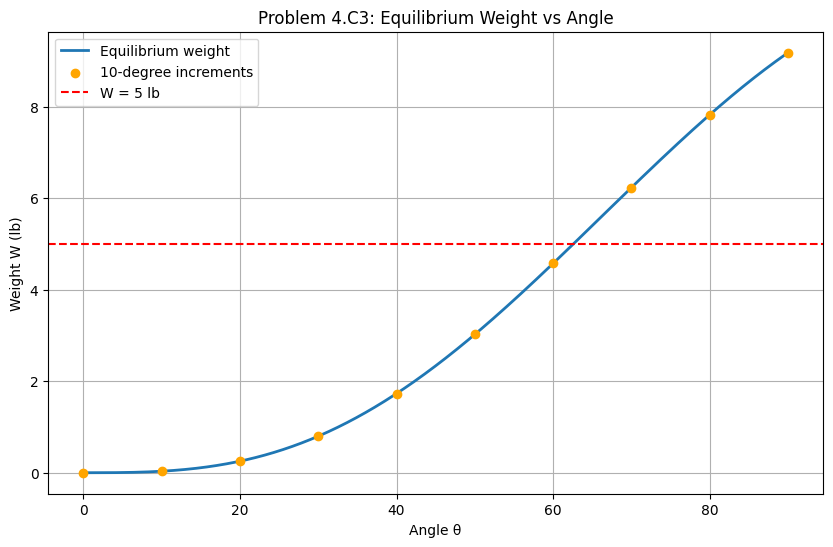

In [12]:
theta_deg = np.linspace(0,90,1000)
theta_rad = np.deg2rad(theta_deg)

plotW = funcW(theta_rad)

plt.figure(figsize=(10,6))
plt.plot(theta_deg, plotW,
         label="Equilibrium weight",
         linewidth=2)

plt.scatter(angles_deg, weights,
            label="10-degree increments",
            color="orange", zorder=3)

plt.axhline(y=5, color="red",
            linestyle="--", label="W = 5 lb")

plt.xlabel("Angle θ")
plt.ylabel("Weight W (lb)")
plt.title("Problem 4.C3: Equilibrium Weight vs Angle")

plt.grid(True)
plt.legend()
plt.show()

In [13]:
solTheta = sp.nsolve(W -5, theta,0.4)
degSolTheta = float(sp.deg(solTheta))

W_check = float(W.subs(theta,solTheta))

print(f"Equilibrium angle: {degSolTheta:.6f} degrees")
print(f"Weight at equilibrium: {W_check:.6f} lb")

Equilibrium angle: 62.607365 degrees
Weight at equilibrium: 5.000000 lb


#### Checking if the answer matches with the given answer
C4sol.jpeg